<center>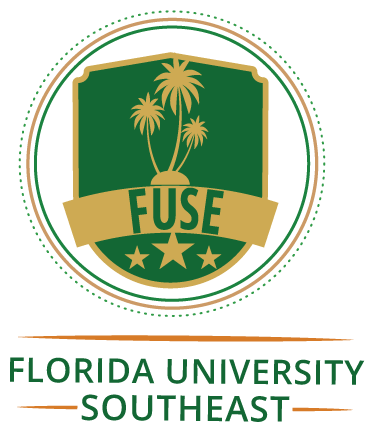 <br>
<br>
 **FUSE AI-201 AI Model Development and Implementation**
<br>
Title: **Real-Time Detection of Fraudulent Credit Card Transactions Using Imbalanced Learning Techniques**
 </center>

### Group 16 Members:
1. Mahteme Girma Mengistu
2. Tewodros Negash Mecheso
3. Kamil Ali Mehammed
4. Fekadu Alemu Meko
5. Elisabeth Zerihun Mekonnen
6. Jerusalem Mulat Mekonnen (MSc in DSE candidate)
7. Naod Mekonnen Yimer
8. Habtamu Miessalie Melaku
9. Naol Melaku Ayana (4th-year Software Engineering, Jimma University)
10. Endalkachew Mideksa Merga

### Introduction
This notebook covers data ingestion, scaling, handling extreme class imbalance using SMOTE, training baseline and advanced gradient boosting models, evaluating performance using **PR-AUC**, and saving the final model artifact for Streamlit deployment.

In [1]:
# Import necessary data science and machine learning libraries
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import xgboost as xgb

# Set styling for plots
sns.set_theme(style='whitegrid')
import warnings

warnings.filterwarnings('ignore')

print('Libraries imported successfully!')

Libraries imported successfully!


## 1. Load and Inspect the Dataset
We load the Kaggle Credit Card Fraud dataset and inspect its dimensions, data types, and target distribution to highlight the extreme class imbalance problem.

In [2]:
# Loading the dataset from the same folder
df = pd.read_csv('creditcard.csv')

# Check and drop duplicate rows
print("Rows before dropping duplicates:", df.shape)
df.drop_duplicates(inplace=True)
print("Rows after dropping duplicates:", df.shape)

print(f'Dataset shape: {df.shape}')
display(df.head())

# Check class distribution
class_counts = df['Class'].value_counts()
class_percentages = df['Class'].value_counts(normalize=True) * 100

Rows before dropping duplicates: (284807, 31)
Rows after dropping duplicates: (283726, 31)
Dataset shape: (283726, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
print('\nClass Distribution Counts:')
print(class_counts)
print('\nClass Distribution Percentages:')
print(class_percentages)


Class Distribution Counts:
Class
0    283253
1       473
Name: count, dtype: int64

Class Distribution Percentages:
Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64


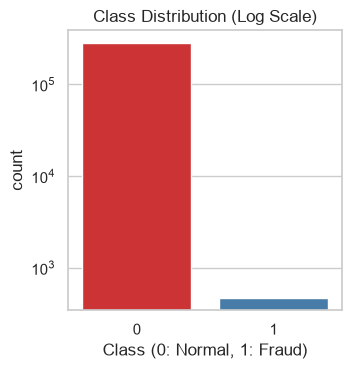

In [4]:
# Set plotting theme
sns.set_theme(style='whitegrid')
plt.figure(figsize=(12, 8))
# 1. Class Imbalance Plot (Log Scale)
plt.subplot(2, 3, 1)
ax = sns.countplot(data=df, x='Class', palette='Set1')
plt.yscale('log')
plt.title('Class Distribution (Log Scale)')
plt.xlabel('Class (0: Normal, 1: Fraud)')

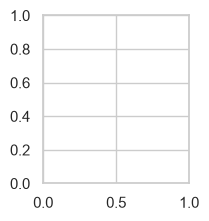

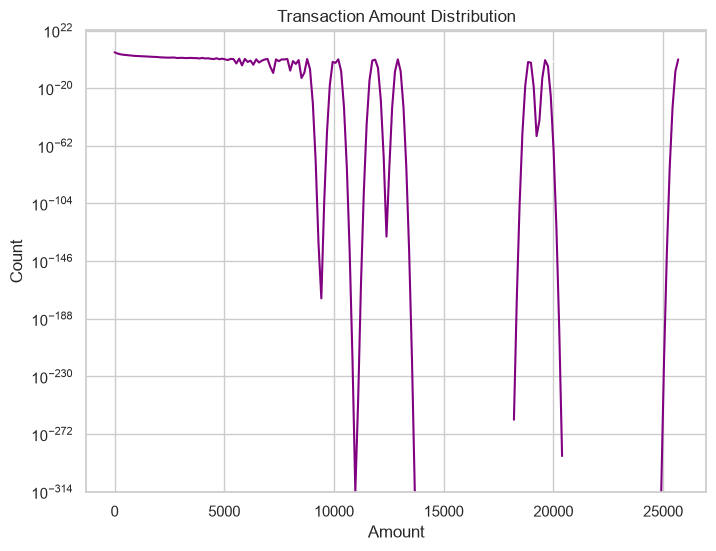

In [5]:

# 2. Transaction Amount Distribution
plt.subplot(2, 3, 2)
plt.figure(figsize=(8, 6))
sns.histplot(
    df['Amount'], bins=50, kde=True, color='purple', log_scale=(False, True)
)
plt.title('Transaction Amount Distribution')
plt.xlabel('Amount')

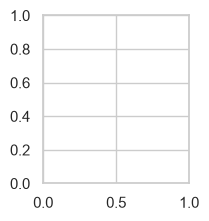

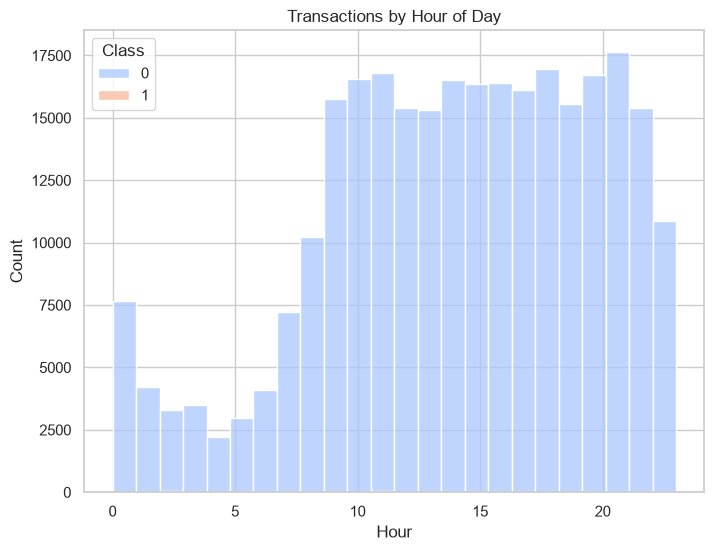

In [6]:

# 3. Time vs Transaction Frequency
plt.subplot(2, 3, 3)
plt.figure(figsize=(8, 6))
df['Hour'] = (df['Time'] // 3600) % 24
sns.histplot(
    data=df, x='Hour', hue='Class', bins=24, multiple='stack', palette='coolwarm'
)
plt.title('Transactions by Hour of Day')

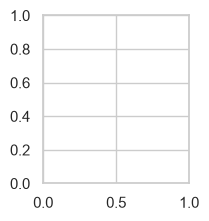

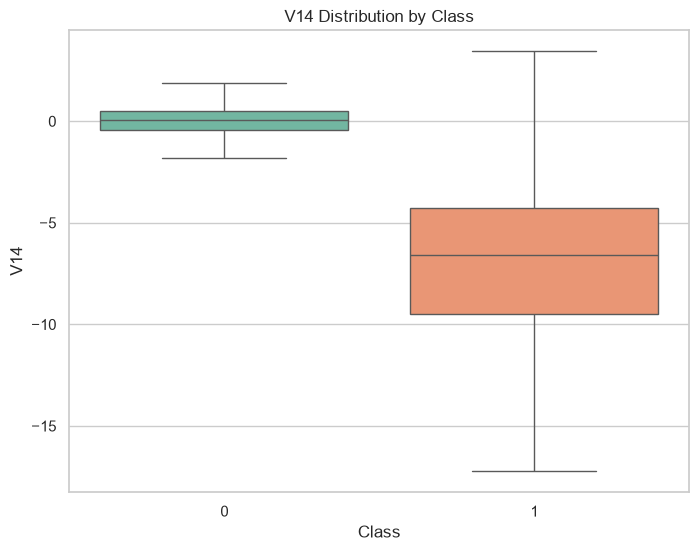

In [7]:
# 4. Key PCA Feature (V14) vs Class (Boxplot)
plt.subplot(2, 3, 4)
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='Class', y='V14', palette='Set2', showfliers=False)
plt.title('V14 Distribution by Class')

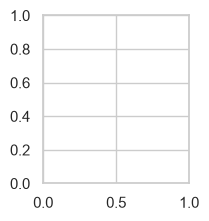

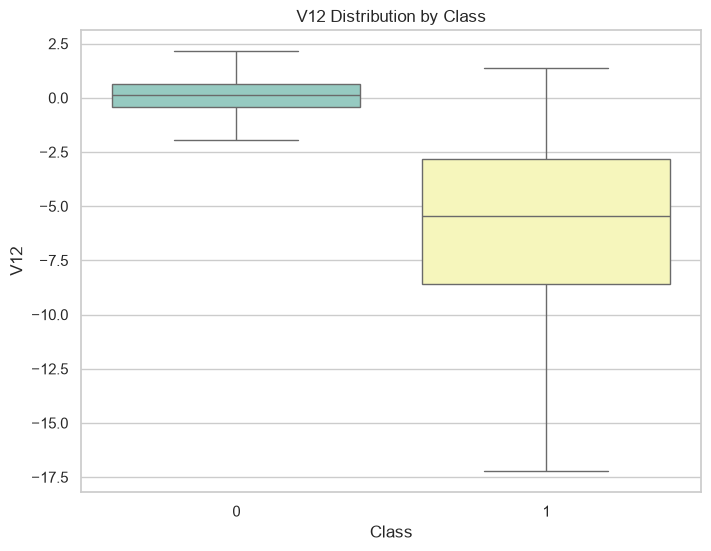

In [8]:
# 5. Key PCA Feature (V12) vs Class (Boxplot)
plt.subplot(2, 3, 5)
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='Class', y='V12', palette='Set3', showfliers=False)
plt.title('V12 Distribution by Class')

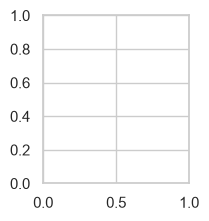

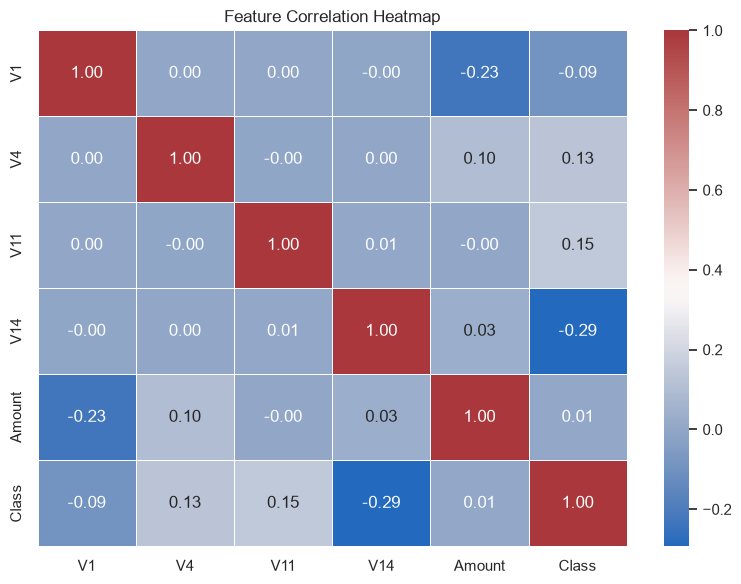

In [9]:
# 6. Correlation Heatmap of Selected Features
plt.subplot(2, 3, 6)
plt.figure(figsize=(8, 6))
sample_cols = ['V1', 'V4', 'V11', 'V14', 'Amount', 'Class']
sns.heatmap(
    df[sample_cols].corr(), annot=True, cmap='vlag', fmt='.2f', linewidths=0.5
)
plt.title('Feature Correlation Heatmap')

plt.tight_layout()
plt.show()

## 2. Preprocessing & Feature Scaling
The features `V1` through `V28` are already PCA-transformed and centered. However, `Time` and `Amount` span wide numerical ranges and require standard scaling before model consumption.

In [10]:
# Drop temporary EDA 'Hour' column and separate Features (X) and Target (y)
# Note: 'Time' and 'Amount' are scaled AFTER train_test_split to prevent data leakage
X = df.drop(['Class', 'Hour'], axis=1)
y = df['Class']

print('Features shape:', X.shape)
print('Target shape:', y.shape)

Features shape: (283726, 30)
Target shape: (283726,)


## 3. Stratified Train-Test Split & SMOTE Balancing
Because fraud is exceedingly rare (~0.17%), we must use a **stratified split** to ensure both training and testing subsets maintain identical proportions of fraudulent classes. Furthermore, we apply **SMOTE** strictly on the training partition to prevent data leakage.

In [11]:
# Stratified train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Train shape:', X_train.shape, 'Test shape:', X_test.shape)

Train shape: (226980, 30) Test shape: (56746, 30)


In [12]:
# Scale Time and Amount on training data only
scaler = StandardScaler()
X_train[['Time','Amount']] = scaler.fit_transform(X_train[['Time','Amount']])
X_test[['Time','Amount']] = scaler.transform(X_test[['Time','Amount']])
print("Scaling complete. Train shape:", X_train.shape, "Test shape:", X_test.shape)

Scaling complete. Train shape: (226980, 30) Test shape: (56746, 30)


In [13]:
print(
    f'Before SMOTE - Training labels shape: {y_train.shape}, Frauds: {sum(y_train)}'
)

# Apply SMOTE to the training set only
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print(
    f'After SMOTE  - Training labels shape: {y_train_resampled.shape}, Frauds: {sum(y_train_resampled)}'
)

Before SMOTE - Training labels shape: (226980,), Frauds: 378
After SMOTE  - Training labels shape: (453204,), Frauds: 226602


## 4. Baseline Model: Logistic Regression
We establish a baseline using Logistic Regression trained on the balanced SMOTE dataset.

In [14]:
print('Training Baseline Model (Logistic Regression)...')
lr_baseline = LogisticRegression(max_iter=1000, random_state=42)
lr_baseline.fit(X_train_resampled, y_train_resampled)

# Predictions & Probabilities
y_pred_lr = lr_baseline.predict(X_test)
y_prob_lr = lr_baseline.predict_proba(X_test)[:, 1]

# Evaluation Metrics
lr_roc_auc = roc_auc_score(y_test, y_prob_lr)
lr_pr_auc = average_precision_score(y_test, y_prob_lr)

print('--- Logistic Regression Baseline Performance ---')
print(f'ROC-AUC Score : {lr_roc_auc:.4f}')
print(f'PR-AUC Score  : {lr_pr_auc:.4f}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred_lr))

Training Baseline Model (Logistic Regression)...
--- Logistic Regression Baseline Performance ---
ROC-AUC Score : 0.9619
PR-AUC Score  : 0.6769

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56651
           1       0.05      0.87      0.10        95

    accuracy                           0.97     56746
   macro avg       0.53      0.92      0.54     56746
weighted avg       1.00      0.97      0.99     56746



## 5. Advanced Model: XGBoost Classifier
Next, we train an XGBoost gradient boosting model designed to handle complex tabular structures and non-linear boundaries.

In [15]:
print('Training Advanced Model (XGBoost)...')
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    eval_metric='aucpr',
    random_state=42,
)
xgb_model.fit(X_train_resampled, y_train_resampled)

# Predictions & Probabilities
y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Evaluation Metrics
xgb_roc_auc = roc_auc_score(y_test, y_prob_xgb)
xgb_pr_auc = average_precision_score(y_test, y_prob_xgb)

print('--- XGBoost Model Performance ---')
print(f'ROC-AUC Score : {xgb_roc_auc:.4f}')
print(f'PR-AUC Score  : {xgb_pr_auc:.4f}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred_xgb))

Training Advanced Model (XGBoost)...
--- XGBoost Model Performance ---
ROC-AUC Score : 0.9751
PR-AUC Score  : 0.7870

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.27      0.84      0.41        95

    accuracy                           1.00     56746
   macro avg       0.63      0.92      0.70     56746
weighted avg       1.00      1.00      1.00     56746



## 6. Confusion Matrix & Performance Visualization
Let's review the confusion matrix for our XGBoost model to evaluate False Positives (blocking good users) versus False Negatives (letting fraud pass).

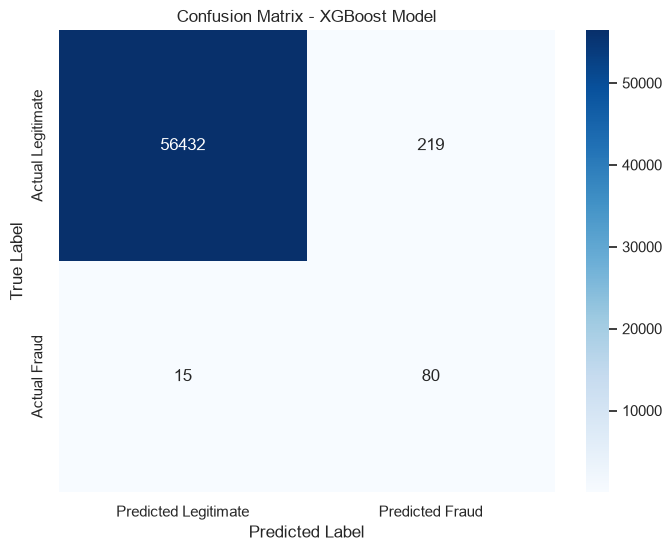

In [16]:
# Compute Confusion Matrix
cm = confusion_matrix(y_test, y_pred_xgb)

# Plotting with Seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Predicted Legitimate', 'Predicted Fraud'],
    yticklabels=['Actual Legitimate', 'Actual Fraud'],
)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - XGBoost Model')
plt.show()

## 7. Save Artifacts for Module 6 Deployment
Finally, we export our trained XGBoost model and standard scaler object to disk using `joblib`. These will be integrated into the Streamlit deployment script.

In [17]:
# Save model and scaler objects
joblib.dump(xgb_model, 'fraud_detector_model.pkl')
joblib.dump(scaler, 'feature_scaler.pkl')

print("Success! Files 'fraud_detector_model.pkl' and 'feature_scaler.pkl' saved.")

Success! Files 'fraud_detector_model.pkl' and 'feature_scaler.pkl' saved.


In [18]:
# Save cleaned and scaled train/test splits for Modules 5 and 6
import joblib
joblib.dump((X_train, y_train, X_test, y_test), 'fraud_data_split.pkl')
print("Saved fraud_data_split.pkl")

Saved fraud_data_split.pkl
